<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/15-unsupervised-learning/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 15: Unsupervised Learning

Every model so far learnt from **labelled** examples: houses with known prices, tumours with known diagnoses, calls with known outcomes. Most data in the world has no labels. Nobody has marked which customers belong together, which transactions are suspicious, or which of 64 pixel values actually matter. **Unsupervised learning** looks for structure in data on its own.

It does three main jobs:

- **Clustering**: find groups of similar examples (customer segments, types of tumour, topics in documents).
- **Dimensionality reduction**: describe data with fewer numbers, to visualise it, compress it, or feed it to another model.
- **Anomaly detection**: find the examples that don't fit (fraud, faulty machines, data entry errors).

There's a catch that runs through the whole module. With no labels, there's no answer key, so there's no simple score that says whether a result is right. Clustering algorithms will **always** return clusters, even in random noise. A large part of doing this well is learning to check whether the structure you found is really there.

**Contents**

1. Learning without labels
2. k-means, built by hand
3. How many clusters?
4. Scaling decides what "similar" means
5. When k-means fails: Gaussian mixtures
6. Hierarchical clustering
7. Density-based clustering: DBSCAN
8. Principal component analysis, built by hand
9. Maps of high-dimensional data: t-SNE and UMAP
10. Anomaly detection
11. Is the structure real?
12. A checklist for unsupervised learning

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/05-files-and-data/data/penguins.csv"
local = Path("data/penguins.csv")
penguins = pd.read_csv(local if local.exists() else DATA_URL)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## 1. Learning without labels

In supervised learning, the data comes in pairs: features `X` and a target `y`, and the model learns the mapping between them. In unsupervised learning there's only `X`. The model has to find something interesting in it without being told what to look for.

Here's the idea in one picture. Below are 300 points with two features each. Your eye finds the groups instantly, without anyone labelling a single point. The algorithms in this module try to do the same, in many dimensions, where eyes can't help.

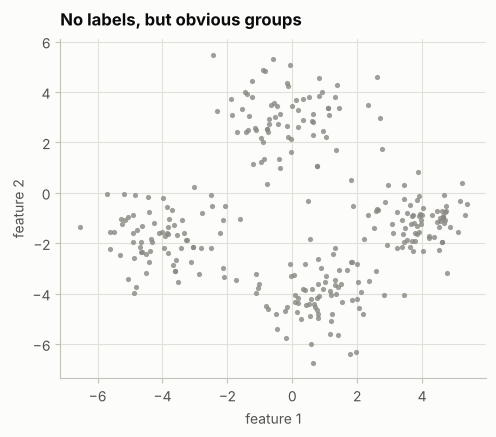

In [3]:
from sklearn.datasets import make_blobs

X_blobs, true_groups = make_blobs(n_samples=300, centers=[[-4, -2], [0, 3], [4, -1], [1, -4]], cluster_std=[1.0, 1.2, 0.8, 0.9],
                                  random_state=0)

fig, ax = plt.subplots(figsize=(5.5, 4.4))
ax.scatter(X_blobs[:, 0], X_blobs[:, 1], s=14, color=MUTED, alpha=0.8)
ax.set_xlabel("feature 1")
ax.set_ylabel("feature 2")
ax.set_title("No labels, but obvious groups")
plt.show()

We made this data ourselves, so we secretly know the true groups (`true_groups`), and we'll use them to check how well each method does. In real problems you won't have them, which is exactly why section 11 matters.

## 2. k-means, built by hand

**k-means** is the most widely used clustering algorithm. You choose the number of clusters, `k`, and it finds `k` centre points (**centroids**) so that each point is close to its nearest centroid. It alternates two simple steps:

1. **Assign**: put each point in the cluster of its nearest centroid.
2. **Update**: move each centroid to the mean of the points assigned to it.

Repeat until nothing changes. Starting centroids are picked at random from the data. This procedure is called **Lloyd's algorithm** (Stuart Lloyd, 1957).

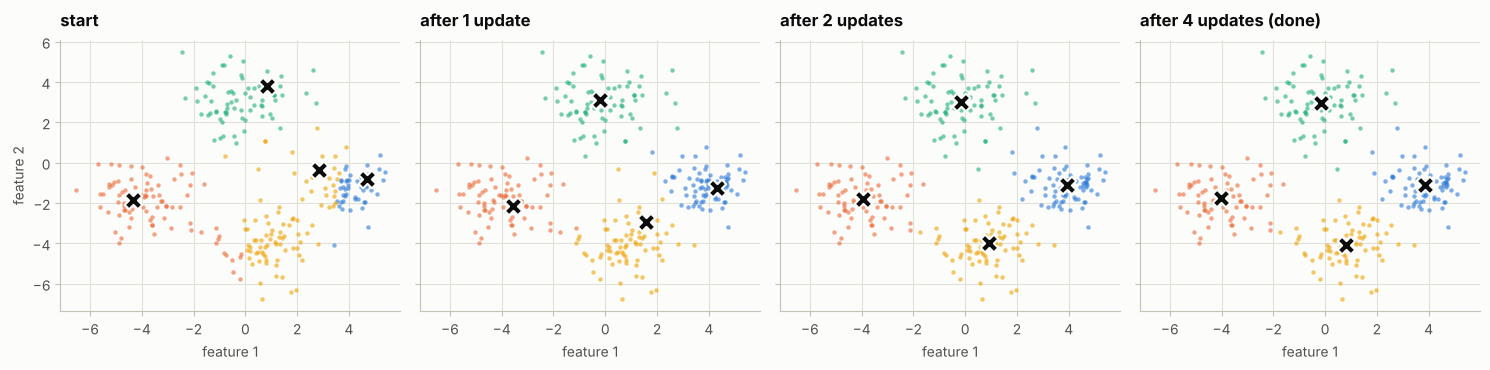

converged after 4 updates


In [4]:
def kmeans_by_hand(X, k, seed=0, max_iter=100):
    rng = np.random.default_rng(seed)
    centroids = X[rng.choice(len(X), size=k, replace=False)]
    history = [centroids]
    for _ in range(max_iter):
        distances = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)    # every point to every centroid
        labels = distances.argmin(axis=1)                                          # 1. assign
        new_centroids = np.array([X[labels == j].mean(axis=0) for j in range(k)])  # 2. update
        history.append(new_centroids)
        if np.allclose(new_centroids, centroids):
            break
        centroids = new_centroids
    return labels, centroids, history


labels_hand, centroids_hand, history = kmeans_by_hand(X_blobs, k=4, seed=3)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, step in zip(axes, [0, 1, 2, len(history) - 1]):
    c = history[step]
    nearest = ((X_blobs[:, None, :] - c[None]) ** 2).sum(axis=2).argmin(axis=1)
    for j in range(4):
        ax.scatter(X_blobs[nearest == j, 0], X_blobs[nearest == j, 1], s=10, color=PALETTE[j], alpha=0.6)
    ax.scatter(c[:, 0], c[:, 1], marker="X", s=160, color=INK, edgecolors=SURFACE, linewidths=1.5)
    ax.set_title("start" if step == 0 else f"after {step} update{'s' if step > 1 else ''}" + (" (done)" if step == len(history) - 1 else ""))
    ax.set_xlabel("feature 1")
axes[0].set_ylabel("feature 2")
fig.tight_layout()
plt.show()
print(f"converged after {len(history) - 1} updates")

The crosses are the centroids. At the start, two of them happen to fall in the same group. After each update they move towards the middle of their points, and within a few steps they settle in the four groups.

What k-means minimises is the **inertia**: the total squared distance from each point to its centroid. Each of the two steps can only lower it (or leave it the same), so the algorithm always stops. scikit-learn's `KMeans` does the same thing, much faster:

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score


def inertia(X, labels, centroids):
    return float(((X - centroids[labels]) ** 2).sum())


km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_blobs)
print(f"inertia by hand:      {inertia(X_blobs, labels_hand, centroids_hand):.2f}")
print(f"scikit-learn inertia: {km.inertia_:.2f}")
print(f"do the two agree on the groups? adjusted Rand index = {adjusted_rand_score(labels_hand, km.labels_):.3f}")

inertia by hand:      574.35
scikit-learn inertia: 574.35
do the two agree on the groups? adjusted Rand index = 1.000


The cluster **numbers** are arbitrary: what one run calls cluster 0, another might call cluster 2. To compare two clusterings, we need a measure that ignores the names. The **adjusted Rand index** (ARI) does this: it counts how many pairs of points are grouped the same way (together in both, or apart in both), and adjusts so that random labels score about 0 and identical groupings score 1. Here it's 1: the same groups, whatever their numbers.

### Bad starts

Because the starting centroids are random, k-means can get stuck in a poor solution: a **local minimum** where neither step can improve things, but a better arrangement exists. Here are 12 runs of our hand-made version, each from a different random start:

In [6]:
results = []
for seed in range(12):
    labels_s, centroids_s, _ = kmeans_by_hand(X_blobs, k=4, seed=seed)
    results.append((inertia(X_blobs, labels_s, centroids_s), adjusted_rand_score(true_groups, labels_s)))
results = pd.DataFrame(results, columns=["inertia", "ARI with the true groups"]).round(3)
print(results.T.to_string())

                               0         1        2        3        4        5        6        7         8        9        10        11
inertia                   574.347  1857.536  574.644  574.347  574.347  574.347  574.347  574.347  1184.404  574.347  574.347  1186.082
ARI with the true groups    0.973     0.586    0.965    0.973    0.973    0.973    0.973    0.973     0.609    0.973    0.973     0.610


Most starts find the same, best solution, but some end up with a higher inertia and groups that don't match the real ones (typically one centroid sharing a group with another while two real groups get merged). Two standard defences, both built into scikit-learn:

- **k-means++** starting points (David Arthur and Sergei Vassilvitskii, 2007): pick the first centroid at random, then pick each next one with probability proportional to its squared distance from the nearest centroid already chosen. Starts spread out, so bad starts become rare. It's scikit-learn's default (`init="k-means++"`).
- **Several runs**: `n_init=10` runs the whole algorithm from 10 starts and keeps the one with the lowest inertia.

## 3. How many clusters?

k-means needs `k` in advance. Two common tools help choose it.

**The elbow method**: plot the inertia for each `k`. Inertia always falls as `k` grows (more centroids means everything is closer to one), so look for the "elbow" where it stops falling quickly.

**The silhouette score** asks, for each point: am I closer to my own cluster than to the next nearest one? For a point `i`, let `a` be its average distance to the other points in its cluster and `b` its average distance to the points of the nearest **other** cluster. Its silhouette is

$$s_i = \frac{b - a}{\max(a, b)}$$

near 1 for a point well inside its cluster, near 0 for a point on a boundary, negative for a point that's probably in the wrong cluster. The average over all points summarises the clustering.

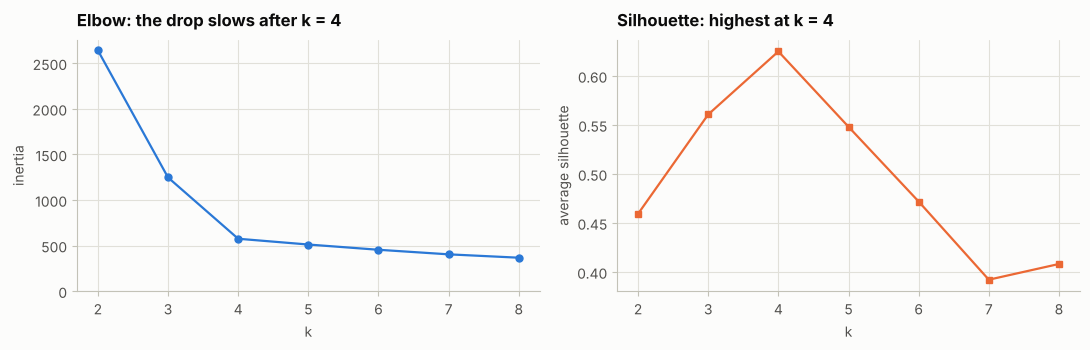

In [7]:
from sklearn.metrics import silhouette_score

ks = range(2, 9)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_blobs).inertia_ for k in ks]
silhouettes = [silhouette_score(X_blobs, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X_blobs)) for k in ks]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(list(ks), inertias, color=PALETTE[0], marker="o", markersize=5)
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")
axes[0].set_ylim(0, None)
axes[0].set_title("Elbow: the drop slows after k = 4")
axes[1].plot(list(ks), silhouettes, color=PALETTE[1], marker="s", markersize=5)
axes[1].set_xlabel("k")
axes[1].set_ylabel("average silhouette")
axes[1].set_title("Silhouette: highest at k = 4")
fig.tight_layout()
plt.show()

On data made of four clear groups, both tools point at 4. Real data is rarely so kind: the elbow is often a gentle curve with no obvious bend, and the silhouette can be nearly flat across several values. When that happens, the honest conclusion is that the data doesn't have one natural number of clusters, and `k` should be chosen by what's useful (section 11 and the mini project).

### Clustering always finds clusters

This is the most important warning in the module. Here are 300 points spread **uniformly** at random over a square: no groups at all. k-means, asked for 4 clusters, returns 4 clusters anyway:

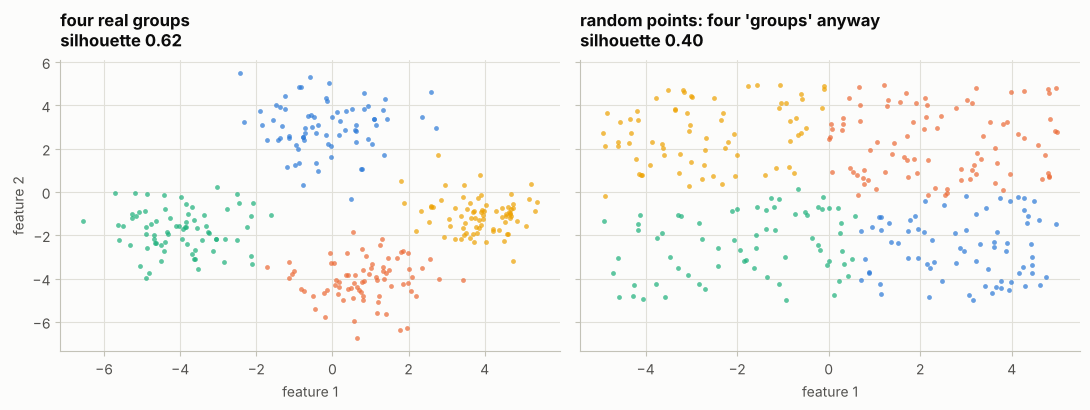

In [8]:
rng = np.random.default_rng(0)
X_uniform = rng.uniform(-5, 5, size=(300, 2))
km_uniform = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_uniform)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, X_demo, labels_demo, title in [(axes[0], X_blobs, km.labels_, "four real groups"),
                                        (axes[1], X_uniform, km_uniform.labels_, "random points: four 'groups' anyway")]:
    for j in range(4):
        ax.scatter(X_demo[labels_demo == j, 0], X_demo[labels_demo == j, 1], s=12, color=PALETTE[j], alpha=0.7)
    ax.set_title(f"{title}\nsilhouette {silhouette_score(X_demo, labels_demo):.2f}")
    ax.set_xlabel("feature 1")
axes[0].set_ylabel("feature 2")
fig.tight_layout()
plt.show()

The random data gets neat, convincing-looking regions. The silhouette is lower, but still positive, and with nothing to compare against it would be easy to believe the four "segments" were real. Section 11 shows a better test: real clusters come back when you repeat the analysis on resampled data; arbitrary ones move around.

## 4. Scaling decides what "similar" means

k-means, like the k-nearest neighbours classifier you built in Modules 1 and 6, works with **distances**, so the scale of each feature matters enormously. Penguins' body mass is measured in grams (values around 4,000) and bill depth in millimetres (values around 17). Unscaled, a difference of 100 grams counts as much as a difference of 100 mm of bill, so body mass dominates every distance.

Let's cluster the penguins into 3 groups from their four measurements, without and with standardisation, and compare the clusters with the species. (The algorithm never sees the species; we only use them afterwards to check.)

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
peng = penguins.dropna(subset=measurements).reset_index(drop=True)
X_peng = peng[measurements]

raw_labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X_peng)
scaled_labels = make_pipeline(StandardScaler(), KMeans(n_clusters=3, n_init=10, random_state=0)).fit_predict(X_peng)

print(f"ARI with species, unscaled: {adjusted_rand_score(peng['species'], raw_labels):.3f}")
print(f"ARI with species, scaled:   {adjusted_rand_score(peng['species'], scaled_labels):.3f}")
print()
print("scaled clusters against species:")
print(pd.crosstab(scaled_labels, peng["species"], rownames=["cluster"]).to_string())

ARI with species, unscaled: 0.331
ARI with species, scaled:   0.793

scaled clusters against species:
species  Adelie  Chinstrap  Gentoo
cluster                           
0           127          5       0
1             0          0     123
2            24         63       0


Unscaled, the clusters are essentially "light, medium and heavy penguins", which mixes species badly. Scaled, every measurement counts equally, and the clusters line up with the species much better: Gentoos form their own cluster almost perfectly, and most of the mistakes are between Adelie and Chinstrap, which have similar body sizes.

Two lessons:

- **Standardise** numeric features before distance-based clustering, unless the units are already comparable and you want them to count as they are.
- **Feature choice is a modelling decision.** Which features you include, and how you scale them, defines what "similar" means. There's no neutral choice. Clustering customers by spending finds spending groups; clustering by age and location finds demographic groups. Both can be "right".

## 5. When k-means fails: Gaussian mixtures

k-means assumes clusters are round blobs of roughly similar size, because each point simply joins the nearest centroid. When groups are stretched, tilted or very different in size, it cuts them in the wrong places.

A **Gaussian mixture model** (GMM) is more flexible. It assumes the data comes from a mix of several normal distributions, each with its own centre, its own shape (a covariance matrix, which can be stretched and tilted) and its own share of the data. It's fitted by the **EM algorithm** (expectation-maximisation), which is a soft version of k-means:

1. **E-step**: for each point, compute the probability that it came from each component.
2. **M-step**: update each component's share, centre and shape using those probabilities as weights.

Here are three tilted, stretched groups:

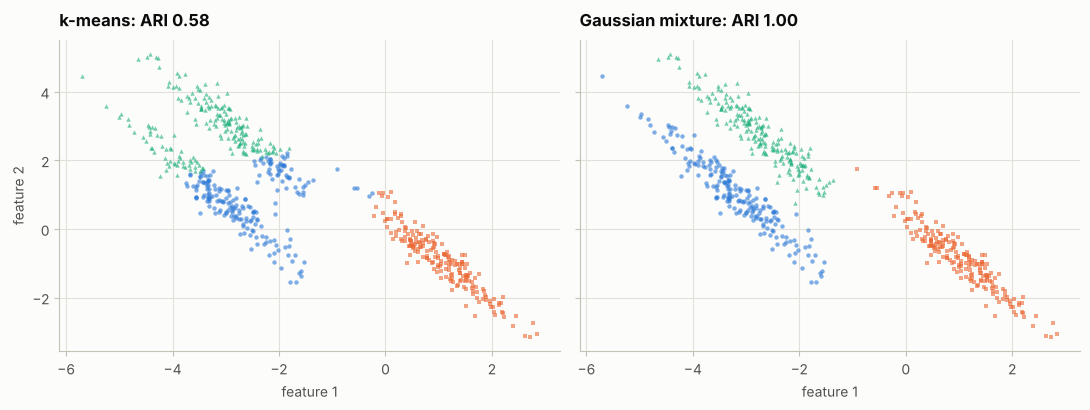

In [10]:
from sklearn.mixture import GaussianMixture

rng = np.random.default_rng(1)
stretch = np.array([[0.6, -0.6], [-0.4, 0.8]])
X_tilted, tilted_groups = make_blobs(n_samples=600, centers=3, cluster_std=[1.0, 1.0, 1.0], random_state=170)
X_tilted = X_tilted @ stretch

km_tilted = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X_tilted)
gmm = GaussianMixture(n_components=3, covariance_type="full", n_init=5, random_state=0).fit(X_tilted)
gmm_labels = gmm.predict(X_tilted)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, labels_demo, name in [(axes[0], km_tilted, "k-means"), (axes[1], gmm_labels, "Gaussian mixture")]:
    for j, marker in zip(range(3), ["o", "s", "^"]):
        ax.scatter(X_tilted[labels_demo == j, 0], X_tilted[labels_demo == j, 1], s=10, color=PALETTE[j], marker=marker, alpha=0.6)
    ax.set_title(f"{name}: ARI {adjusted_rand_score(tilted_groups, labels_demo):.2f}")
    ax.set_xlabel("feature 1")
axes[0].set_ylabel("feature 2")
fig.tight_layout()
plt.show()

k-means slices across the stretched groups, because it can only draw straight boundaries halfway between centroids. The Gaussian mixture learns each group's shape and recovers them almost exactly.

GMMs have two more advantages:

- **Soft assignments.** `predict_proba` gives each point's probability of belonging to each component, so points between groups are marked as uncertain instead of being forced into one.
- **A principled way to choose the number of components.** A GMM is a probability model, so we can compare fits with the **BIC** (Bayesian information criterion): the log-likelihood, penalised for the number of parameters. Lower is better.

In [11]:
probabilities = gmm.predict_proba(X_tilted)
uncertain = probabilities.max(axis=1) < 0.9
print(f"points with less than 90% probability for any one component: {uncertain.sum()} of {len(X_tilted)}")

bic = {k: GaussianMixture(n_components=k, n_init=3, random_state=0).fit(X_tilted).bic(X_tilted) for k in range(1, 7)}
print("BIC by number of components:", {k: round(v) for k, v in bic.items()})
print("lowest BIC:", min(bic, key=bic.get))

points with less than 90% probability for any one component: 1 of 600
BIC by number of components: {1: 4273, 2: 3509, 3: 3062, 4: 3093, 5: 3120, 6: 3163}
lowest BIC: 3


The BIC is lowest at 3, the true number. The price of this flexibility is more parameters to estimate: with many features, a full covariance matrix per component needs a lot of data, and `covariance_type="diag"` (stretched along the axes only) or `"spherical"` (round, like k-means) are safer choices.

## 6. Hierarchical clustering

**Agglomerative hierarchical clustering** builds clusters from the bottom up:

1. Start with every point as its own cluster.
2. Merge the two **closest** clusters.
3. Repeat until everything is one cluster.

The result isn't one clustering but a whole tree of merges, drawn as a **dendrogram**. Cutting the tree at a chosen height gives any number of clusters, and the heights of the merges show how distinct the groups are. It's especially useful for small datasets and for exploring structure at several levels at once, such as species within genera within families.

Here's a dendrogram of 40 penguins, using the scaled measurements:

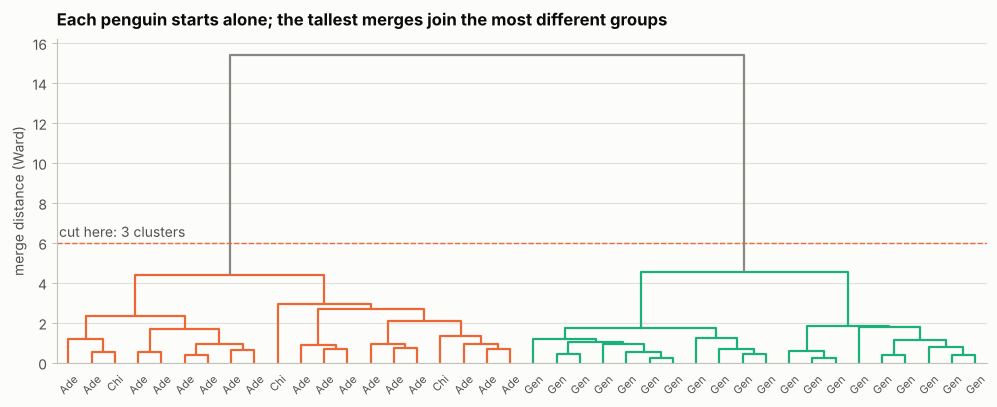

In [12]:
from scipy.cluster.hierarchy import dendrogram, linkage

sample = peng.sample(40, random_state=2)
Z_sample = StandardScaler().fit(X_peng).transform(sample[measurements])
merges = linkage(Z_sample, method="ward")

fig, ax = plt.subplots(figsize=(12, 4.2))
dendrogram(merges, labels=sample["species"].str[:3].tolist(), leaf_font_size=8, color_threshold=6,
           above_threshold_color=MUTED, ax=ax)
ax.axhline(6, color=PALETTE[1], linestyle="--", linewidth=1)
ax.text(1, 6.3, "cut here: 3 clusters", color=INK_2)
ax.set_ylabel("merge distance (Ward)")
ax.set_title("Each penguin starts alone; the tallest merges join the most different groups")
ax.grid(axis="x", visible=False)
plt.show()

Read it from the bottom: each leaf is one penguin (labelled with the first three letters of its species, which the algorithm didn't see). Short links join very similar penguins; the tall links near the top join groups that are very different. The Gentoos separate from the others at the highest merge. Cutting the tree at the dashed line gives three clusters.

What "closest clusters" means is the **linkage**, and it changes the results a lot:

| linkage | distance between two clusters | tends to find |
|---|---|---|
| single | the closest pair of points | long, chained, irregular shapes; sensitive to noise |
| complete | the farthest pair of points | compact clusters of similar diameter |
| average | the average over all pairs | a compromise |
| Ward | the increase in total within-cluster variance | compact, similar-sized clusters, like k-means |

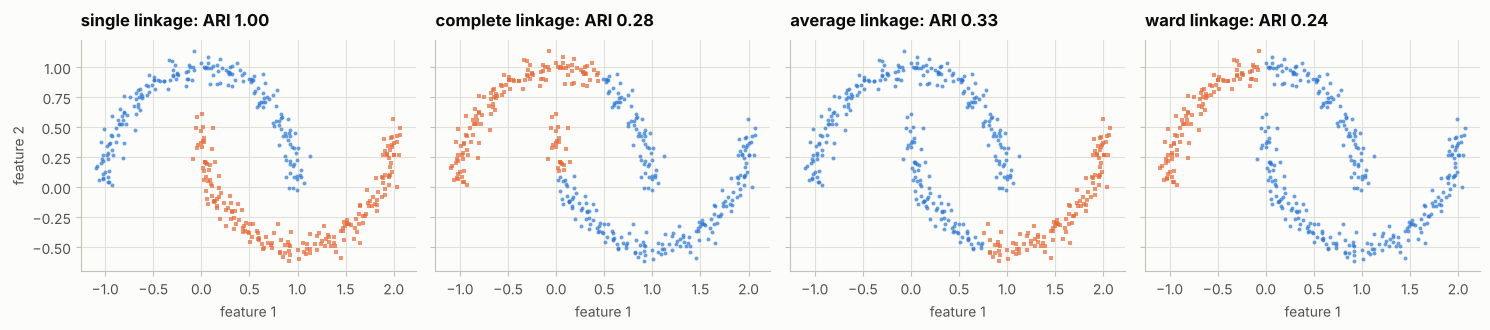

In [13]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import make_moons

X_moons, moon_groups = make_moons(n_samples=400, noise=0.06, random_state=0)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, method in zip(axes, ["single", "complete", "average", "ward"]):
    labels_demo = AgglomerativeClustering(n_clusters=2, linkage=method).fit_predict(X_moons)
    for j, marker in zip(range(2), ["o", "s"]):
        ax.scatter(X_moons[labels_demo == j, 0], X_moons[labels_demo == j, 1], s=8, color=PALETTE[j], marker=marker, alpha=0.7)
    ax.set_title(f"{method} linkage: ARI {adjusted_rand_score(moon_groups, labels_demo):.2f}")
    ax.set_xlabel("feature 1")
axes[0].set_ylabel("feature 2")
fig.tight_layout()
plt.show()

Only **single linkage** separates the two moons, because it follows chains of nearby points along each curve. The others look for compact groups and cut both moons in half. With more noise between the moons, single linkage would fail too, since a single bridge of points is enough to chain the two together.

Hierarchical clustering compares every pair of points, so its memory and time grow with the **square** of the number of points (or worse). It's comfortable up to some tens of thousands of points, not millions.

## 7. Density-based clustering: DBSCAN

**DBSCAN** (Martin Ester and colleagues, 1996) defines clusters as **dense regions** separated by sparse ones. It has two settings: a radius `eps` and a count `min_samples`.

- A **core point** has at least `min_samples` points (including itself) within distance `eps`.
- Core points within `eps` of each other belong to the same cluster, and clusters grow through chains of core points.
- A **border point** isn't core, but is within `eps` of a core point; it joins that cluster.
- Everything else is **noise**, labelled `-1`.

So DBSCAN finds clusters of any shape, decides the number of clusters itself, and marks outliers instead of forcing them into a cluster. Here it is on the moons, with some random noise points added:

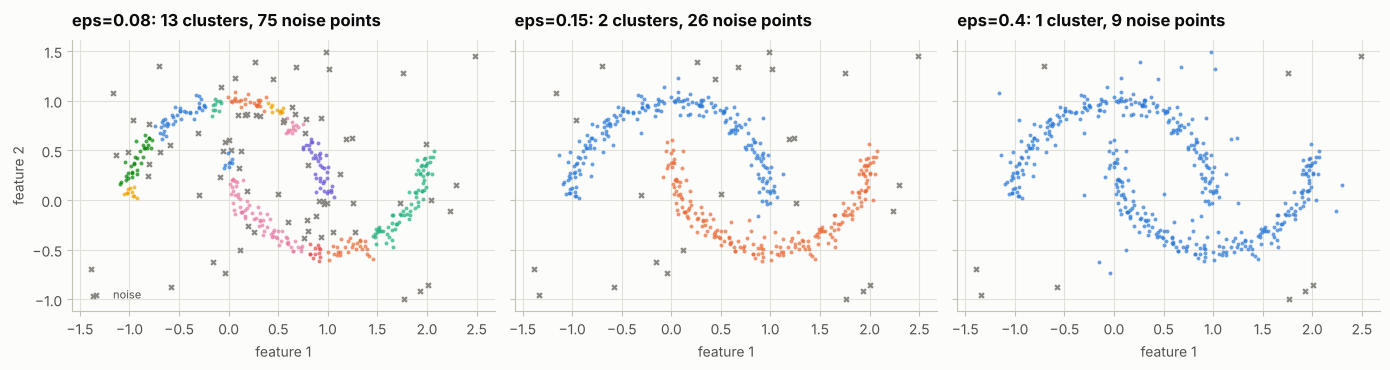

In [14]:
from sklearn.cluster import DBSCAN

rng = np.random.default_rng(0)
X_noisy = np.vstack([X_moons, rng.uniform([-1.5, -1], [2.5, 1.5], size=(40, 2))])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, eps in zip(axes, [0.08, 0.15, 0.4]):
    labels_demo = DBSCAN(eps=eps, min_samples=5).fit_predict(X_noisy)
    n_clusters = len(set(labels_demo)) - (1 if -1 in labels_demo else 0)
    ax.scatter(X_noisy[labels_demo == -1, 0], X_noisy[labels_demo == -1, 1], s=12, color=MUTED, marker="x", label="noise")
    for j in range(n_clusters):
        ax.scatter(X_noisy[labels_demo == j, 0], X_noisy[labels_demo == j, 1], s=8, color=PALETTE[j % 8], alpha=0.7)
    ax.set_title(f"eps={eps}: {n_clusters} cluster{'s' if n_clusters != 1 else ''}, {np.sum(labels_demo == -1)} noise points")
    ax.set_xlabel("feature 1")
axes[0].set_ylabel("feature 2")
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

With `eps` too small, DBSCAN breaks the data into many small clusters and calls a lot of genuine points noise. With `eps` too large, everything merges into one cluster. In between, it finds the two moons and marks most of the scattered points as noise.

A common way to choose `eps`: compute each point's distance to its `min_samples`-th nearest neighbour, sort these distances, and look for the bend where they start rising sharply. Points in dense regions have small distances; noise points have large ones.

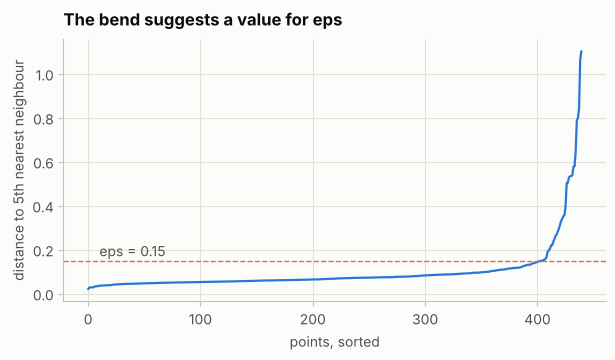

In [15]:
from sklearn.neighbors import NearestNeighbors

distances, _ = NearestNeighbors(n_neighbors=5).fit(X_noisy).kneighbors(X_noisy)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.sort(distances[:, -1]), color=PALETTE[0])
ax.axhline(0.15, color=PALETTE[1], linestyle="--", linewidth=1)
ax.text(10, 0.17, "eps = 0.15", color=INK_2)
ax.set_xlabel("points, sorted")
ax.set_ylabel("distance to 5th nearest neighbour")
ax.set_title("The bend suggests a value for eps")
plt.show()

DBSCAN's weakness is **varying density**: one `eps` can't suit a tight cluster and a spread-out one at the same time. **HDBSCAN** (Ricardo Campello and colleagues, 2013), available as `sklearn.cluster.HDBSCAN`, removes the need to choose `eps` by effectively trying all values and keeping the clusters that persist longest. It's often the better starting point for density-based clustering.

## 8. Principal component analysis, built by hand

Now the second job: describing data with fewer numbers. **Principal component analysis** (PCA) finds new axes for the data:

- The **first principal component** is the direction along which the data varies the most.
- The **second** is the direction of most remaining variation, at right angles to the first.
- And so on: as many components as there are features, each capturing less variation than the one before.

Keeping only the first few components gives a compressed description that preserves as much of the variation as possible. Each component is a weighted combination of the original features, and the weights (called **loadings**) say what the component means.

PCA is linear algebra from Module 9. Centre the data (subtract each feature's mean), then compute the **singular value decomposition** `X = U S Vᵀ`. The rows of `Vᵀ` are the components, and the variance along each is `S² / (n - 1)`.

In [16]:
from sklearn.decomposition import PCA

Z_peng = StandardScaler().fit_transform(X_peng)        # standardised, so each measurement counts equally


def pca_by_hand(X, n_components):
    centred = X - X.mean(axis=0)
    U, S, Vt = np.linalg.svd(centred, full_matrices=False)
    variance = S ** 2 / (len(X) - 1)
    scores = centred @ Vt[:n_components].T             # the data in the new coordinates
    return scores, Vt[:n_components], variance / variance.sum()


scores_hand, components_hand, ratio_hand = pca_by_hand(Z_peng, 2)
pca_peng = PCA(n_components=2).fit(Z_peng)
print("share of variance, by hand:      ", ratio_hand.round(3), "(all four components)")
print("share of variance, scikit-learn: ", pca_peng.explained_variance_ratio_.round(3))
print("same components (up to sign)?    ", np.allclose(np.abs(components_hand), np.abs(pca_peng.components_)))
print()
print(pd.DataFrame(components_hand, index=["PC1", "PC2"], columns=measurements).round(2).to_string())

share of variance, by hand:       [0.688 0.193 0.091 0.027] (all four components)
share of variance, scikit-learn:  [0.688 0.193]
same components (up to sign)?     True

     bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
PC1            0.46           -0.4               0.58         0.55
PC2           -0.60           -0.8              -0.00        -0.08


The first two components describe nearly 90% of the variation in the four measurements, and the last two only about 12% between them. The table of loadings explains them:

- **PC1** has large positive weights on flipper length, body mass and bill length, and a negative weight on bill depth: it's roughly "overall size, with long shallow bills". Penguins with high PC1 scores are big.
- **PC2** is mostly bill depth (and some bill length): it separates deep-billed from shallow-billed penguins of similar size.

The **sign** of a component is arbitrary: flipping all its weights describes the same axis pointing the other way. That's why we compare absolute values with scikit-learn, which picks a sign by its own convention.

Here are the penguins plotted on the first two components. The algorithm didn't see the species; the colours are added afterwards:

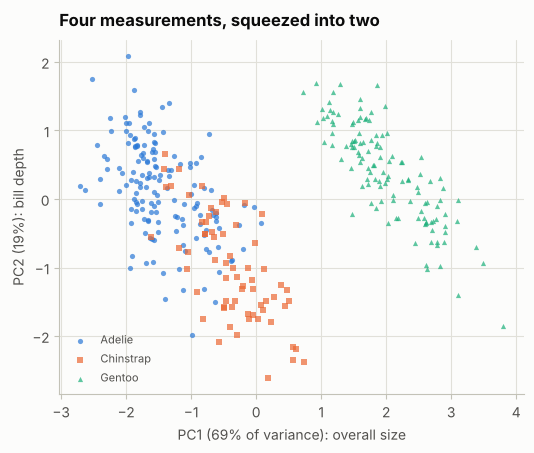

In [17]:
fig, ax = plt.subplots(figsize=(6, 4.6))
for i, (species, marker) in enumerate(zip(sorted(peng["species"].unique()), ["o", "s", "^"])):
    mask = (peng["species"] == species).to_numpy()
    ax.scatter(scores_hand[mask, 0], scores_hand[mask, 1], s=14, color=PALETTE[i], marker=marker, alpha=0.7, label=species)
ax.set_xlabel(f"PC1 ({ratio_hand[0]:.0%} of variance): overall size")
ax.set_ylabel(f"PC2 ({ratio_hand[1]:.0%}): bill depth")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Four measurements, squeezed into two")
plt.show()

Four dimensions became two, and the species structure survives: Gentoos (big, shallow bills) on the right, Adelies and Chinstraps on the left, partly overlapping.

### PCA on images

PCA earns its keep with many features. scikit-learn includes 1,797 small images of handwritten digits, each 8 × 8 pixels: 64 features per image.

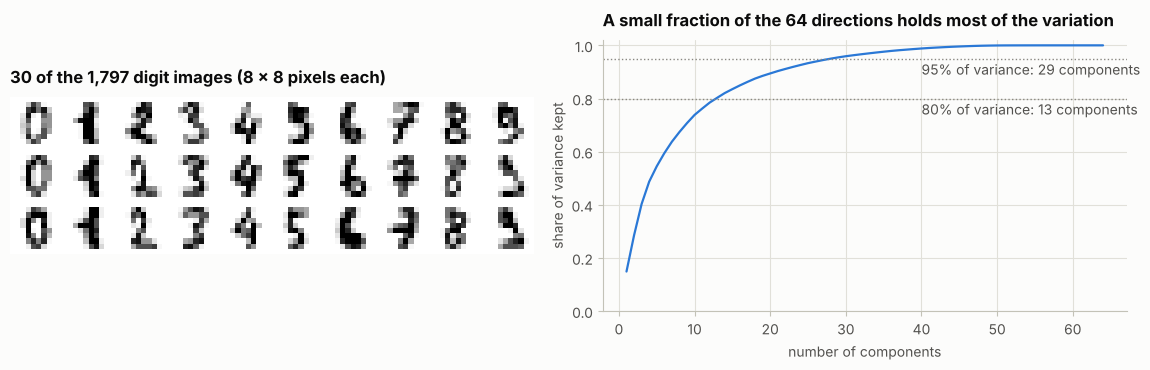

In [18]:
from sklearn.datasets import load_digits

digits = load_digits()
X_digits, y_digits = digits.data, digits.target
pca_digits = PCA().fit(X_digits)
cumulative = np.cumsum(pca_digits.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
gallery = axes[0]
tiles = [[np.pad(X_digits[r * 10 + c].reshape(8, 8), 1) for c in range(10)] for r in range(3)]   # a blank border around each
gallery.imshow(np.vstack([np.hstack(row) for row in tiles]), cmap="Greys")
gallery.set_title("30 of the 1,797 digit images (8 × 8 pixels each)")
gallery.axis("off")
gallery.grid(False)
axes[1].plot(np.arange(1, 65), cumulative, color=PALETTE[0])
gallery.set_aspect("equal")
for target in [0.8, 0.95]:
    n_needed = int(np.searchsorted(cumulative, target)) + 1
    axes[1].axhline(target, color=MUTED, linestyle=":", linewidth=1)
    axes[1].text(40, target - 0.06, f"{target:.0%} of variance: {n_needed} components", color=INK_2)
axes[1].set_xlabel("number of components")
axes[1].set_ylabel("share of variance kept")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("A small fraction of the 64 directions holds most of the variation")
fig.tight_layout()
plt.show()

A fraction of the 64 components keeps 80% of the variation, and fewer than half keep 95%. Many pixels are nearly always blank (the edges), and neighbouring pixels move together, so the images really live in a much smaller space than 64 dimensions.

We can see what's lost by **reconstructing** images from a few components: project onto the components, then map back (`inverse_transform`).

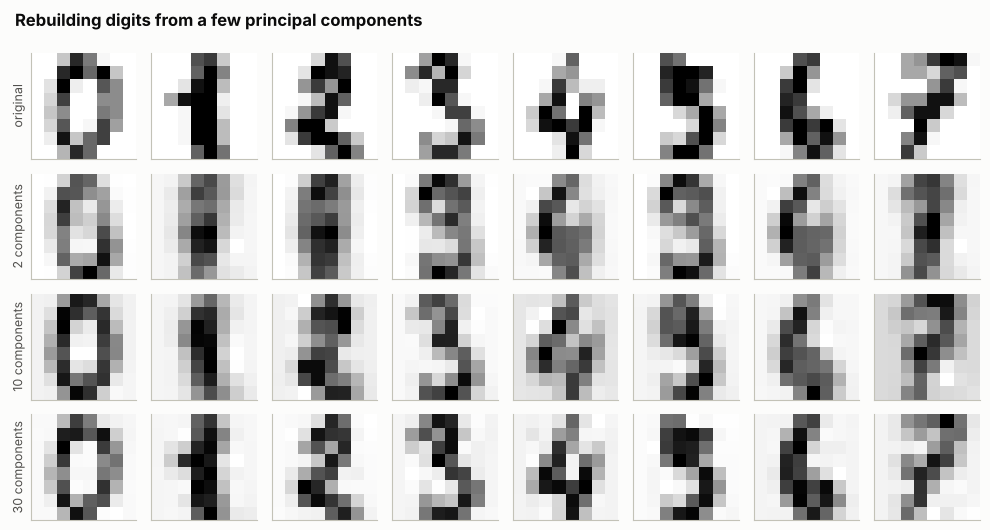

In [19]:
fig, axes = plt.subplots(4, 8, figsize=(10, 5.4))
for col in range(8):
    axes[0, col].imshow(X_digits[col].reshape(8, 8), cmap="Greys")
    for row, n_comp in zip(range(1, 4), [2, 10, 30]):
        pca_n = PCA(n_components=n_comp).fit(X_digits)
        rebuilt = pca_n.inverse_transform(pca_n.transform(X_digits[col:col + 1]))
        axes[row, col].imshow(rebuilt.reshape(8, 8), cmap="Greys")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
for row, label in enumerate(["original", "2 components", "10 components", "30 components"]):
    axes[row, 0].set_ylabel(label, fontsize=9)
fig.suptitle("Rebuilding digits from a few principal components", x=0.02, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

With 2 components, the reconstructions are blurry blobs: enough to tell a 0 from a 1, not much more. With 10, most digits are recognisable. With 30, they're nearly indistinguishable from the originals, using less than half the numbers.

Uses of PCA:

- **Visualisation**: plot the first two or three components.
- **Compression and speed**: fewer features for a later model. (With modern models and hardware this matters less than it used to, and it can throw away information the later model needed.)
- **Removing noise**: the last components often capture mostly noise.
- **Understanding**: the loadings show which features vary together.

Its limit is that it's **linear**: it can only find flat directions. Data that lies on a curved surface needs other tools.

## 9. Maps of high-dimensional data: t-SNE and UMAP

Here are the digits on their first two principal components, coloured by their true digit (which PCA didn't see):

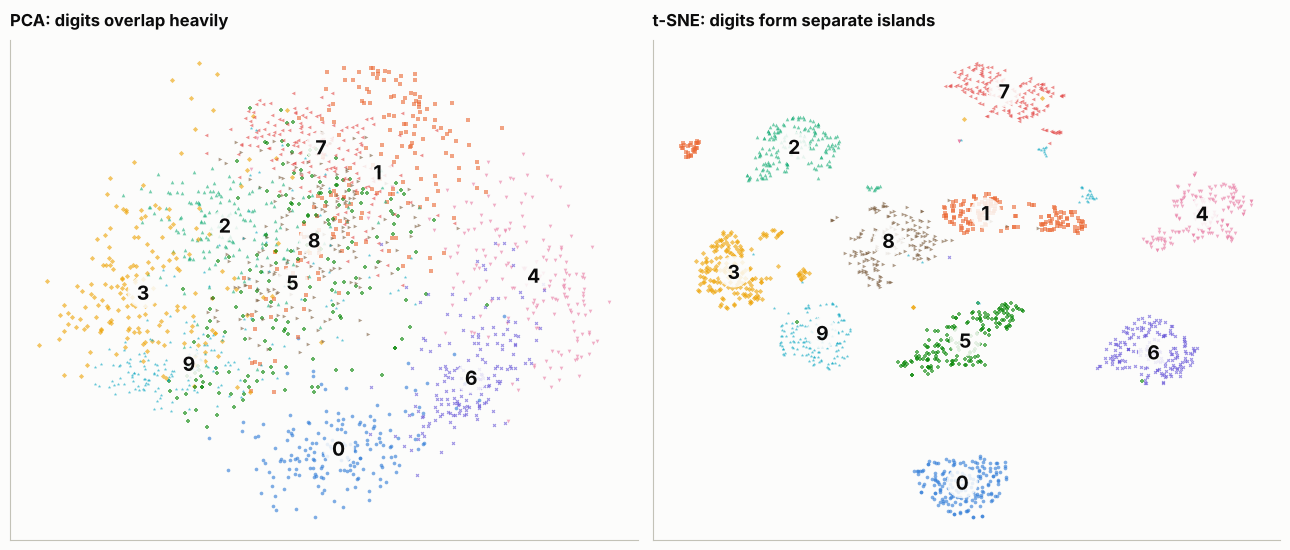

In [20]:
from sklearn.manifold import TSNE

digit_colours = PALETTE + ["#7a5c3e", "#00a3bf"]        # ten digits need two extra, clearly different colours
digit_markers = ["o", "s", "^", "D", "v", "P", "X", "<", ">", "*"]


def plot_digit_map(coords, ax, title):
    for d in range(10):
        mask = y_digits == d
        ax.scatter(coords[mask, 0], coords[mask, 1], s=7, color=digit_colours[d], marker=digit_markers[d], alpha=0.6)
        cx, cy = np.median(coords[mask], axis=0)
        ax.text(cx, cy, str(d), fontsize=14, fontweight="bold", ha="center", va="center", color=INK,
                bbox={"boxstyle": "circle,pad=0.2", "facecolor": SURFACE, "edgecolor": AXIS, "alpha": 0.85})
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)


coords_pca = PCA(n_components=2).fit_transform(X_digits)
coords_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(X_digits)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
plot_digit_map(coords_pca, axes[0], "PCA: digits overlap heavily")
plot_digit_map(coords_tsne, axes[1], "t-SNE: digits form separate islands")
fig.tight_layout()
plt.show()

PCA's two flat directions keep less than a third of the variation, so most digits pile on top of each other. **t-SNE** (t-distributed stochastic neighbour embedding, Laurens van der Maaten and Geoffrey Hinton, 2008) takes a different approach. It doesn't try to preserve distances in general; it tries to keep each point's **nearest neighbours** close in the map. Points that are neighbours in 64 dimensions should be neighbours in 2. The result shows the ten digits as clear islands, discovered without any labels. (Some digits split into two islands, such as two styles of writing a 1, and a few points land on the wrong island: those are digits that really do look like another digit.)

t-SNE maps are beautiful and easy to over-read. Things to know:

- **Distances between islands mean little.** Two clusters far apart on the map may not be more different than two that are close.
- **Cluster sizes mean little.** t-SNE expands dense clusters and shrinks sparse ones, so a tight cluster and a loose one can look the same size.
- **The map depends on settings and randomness.** The main setting, `perplexity`, is roughly the number of neighbours each point pays attention to (typical values 5 to 50). Different values, or a different `random_state`, give different-looking maps.
- **It's for looking, not for modelling.** There's no way to place new points on an existing map, and clustering the map's coordinates can produce groups that are artefacts of the method.

**UMAP** (uniform manifold approximation and projection, Leland McInnes and colleagues, 2018) is a newer method with similar goals. It's usually faster on large data, tends to keep more of the global arrangement of clusters, and can place new points onto an existing map. It isn't part of scikit-learn; install it with `pip install umap-learn` and use it like this:

```python
import umap
coords_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(X_digits)
```

The same cautions apply to UMAP maps.

## 10. Anomaly detection

The third job is finding the points that don't fit: a fraudulent transaction, a failing sensor, a typing error in a spreadsheet. It's usually unsupervised because anomalies are rare, varied, and often unlabelled: you rarely have a list of every kind of fraud in advance.

The simplest approach scores each value by how many standard deviations it is from the mean (a **z-score**) and flags anything beyond 3. That fails in two common situations: the outliers themselves pull the mean and inflate the standard deviation, and data with several groups has no single "normal" centre. A **robust z-score** uses the median and the median absolute deviation instead, which outliers barely affect.

For several features at once, two widely used methods:

- **Isolation Forest** (Fei Tony Liu, Kai Ming Ting and Zhi-Hua Zhou, 2008) builds random trees that split on random features at random thresholds. An unusual point gets isolated in its own leaf after only a few splits; a normal point, surrounded by others, takes many. The average depth needed is the anomaly score.
- **Local Outlier Factor** (LOF, Markus Breunig and colleagues, 2000) compares each point's local density with its neighbours' densities. A point in a much sparser spot than its neighbours is an outlier, even if a different region of the data is just as sparse overall.

Let's test them on data where we know the answer: two groups of normal points of different spreads, plus 20 anomalies scattered around:

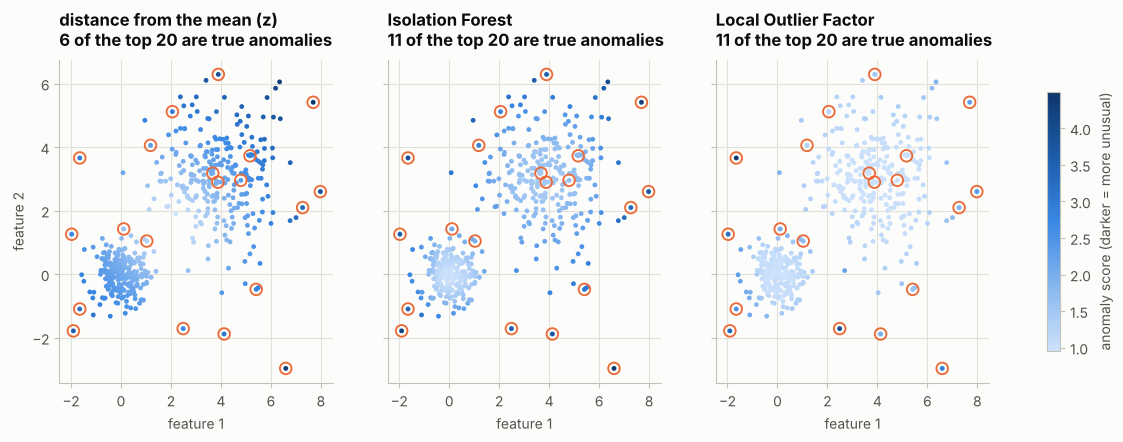

In [21]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

rng = np.random.default_rng(4)
normal = np.vstack([rng.normal([0, 0], 0.5, size=(250, 2)), rng.normal([4, 3], 1.2, size=(250, 2))])
anomalies = rng.uniform([-3, -3], [8, 7], size=(20, 2))
X_anom = np.vstack([normal, anomalies])
is_anomaly = np.r_[np.zeros(500, dtype=bool), np.ones(20, dtype=bool)]

z = (X_anom - X_anom.mean(axis=0)) / X_anom.std(axis=0)
scores = {
    "distance from the mean (z)": np.sqrt((z ** 2).sum(axis=1)),
    "Isolation Forest": -IsolationForest(random_state=0).fit(X_anom).score_samples(X_anom),
    "Local Outlier Factor": -LocalOutlierFactor(n_neighbors=20).fit(X_anom).negative_outlier_factor_,
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (name, score) in zip(axes, scores.items()):
    flagged = np.argsort(-score)[:20]                        # the 20 highest scores
    hits = is_anomaly[flagged].sum()
    sc = ax.scatter(X_anom[:, 0], X_anom[:, 1], c=score, cmap=SEQUENTIAL, s=12)
    ax.scatter(X_anom[is_anomaly, 0], X_anom[is_anomaly, 1], s=70, facecolors="none", edgecolors=PALETTE[1], linewidths=1.3)
    ax.set_title(f"{name}\n{hits} of the top 20 are true anomalies")
    ax.set_xlabel("feature 1")
axes[0].set_ylabel("feature 2")
fig.colorbar(sc, ax=axes, label="anomaly score (darker = more unusual)", shrink=0.8)
plt.show()

The orange rings mark the true anomalies. Distance from the overall mean treats the whole outer edge of the big, loose group as unusual, so most of its top 20 are ordinary points. Isolation Forest and LOF each find about half of the anomalies, nearly twice as many.

Look at the anomalies they miss: most of them landed inside the big, loose group, where they're surrounded by normal points. They were generated differently, but nothing in the data distinguishes them from normal points, so no method could find them. That's an honest limit of anomaly detection: it finds points that **look** unusual, which isn't always the same as points that **are** unusual.

Practical notes:

- All these methods produce a **score**, and you choose how many to flag. That's a threshold decision like in Module 13: how many cases can someone investigate, and what does a missed anomaly cost?
- The `contamination` setting in scikit-learn only sets that threshold (the expected share of anomalies); it doesn't change the scores.
- **An anomaly isn't necessarily an error.** It's a point unlike the others. It might be fraud, a broken sensor, a typing mistake, or your most valuable customer. Look at the flagged cases before deleting or acting on them.
- If you do have some labelled anomalies, use them to **evaluate** (as here: how many of the top 20 are real), even if you can't train on them.

## 11. Is the structure real?

Without labels, how do you know a clustering means anything? There's no single test, but several checks together build confidence.

**Internal measures** (silhouette, inertia, BIC) use only the data. They say whether clusters are compact and separated, but section 3 showed that random data gets decent-looking numbers too, and each measure favours certain shapes (silhouette favours round clusters).

**External measures** (ARI against known labels) need labels, so they're only available for checking a method on data where you know the answer, or for comparing clusters with some known category (as with the penguin species).

**Stability**: real structure should come back when you change the data a little. Draw a bootstrap sample, cluster it, use that model to assign **all** the points, and compare with the clustering of the full data using the ARI. Repeat many times. Clusters that reappear every time are probably real; clusters that change from sample to sample are probably artefacts.

In [22]:
def stability(X, k, n_boot=30, seed=0):
    """Average ARI between the full-data clustering and clusterings of bootstrap samples."""
    rng = np.random.default_rng(seed)
    reference = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    aris = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(X), len(X))
        resampled = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X[idx])
        aris.append(adjusted_rand_score(reference.labels_, resampled.predict(X)))
    return np.mean(aris)


rows = {f"k = {k}": {"blobs (4 real groups)": stability(X_blobs, k), "uniform (no groups)": stability(X_uniform, k)} for k in range(2, 7)}
pd.DataFrame(rows).T.round(3)

,blobs (4 real groups),uniform (no groups)
k = 2,0.988,0.565
k = 3,0.987,0.676
k = 4,0.993,0.869
k = 5,0.893,0.747
k = 6,0.766,0.769


On the blobs, `k` from 2 to 4 is almost perfectly stable: with 2 or 3 clusters, the algorithm merges neighbouring real groups, and does it the same way every time. Beyond 4, it has to split real groups, and does that differently each time, so stability drops. On the uniform data, every `k` is clearly less stable than the real groups. Some values still score fairly well: cutting a square into four quarters gives roughly the same cut every time, even though the quarters aren't real groups.

So stability is evidence, not proof. It can rule out structure that keeps moving, and it's most useful **compared with a reference**: if your data's clusters are no more stable than clusters of random data with the same spread, they probably aren't real.

**Usefulness** is the last and often the most important check. A customer segmentation is good if it leads to better decisions: different products, messages or services that work better for each segment. That's tested the way any decision is tested: try it, and measure the result. Unsupervised learning finds candidate structure; whether that structure is worth using is a question about the world, not the algorithm.

## 12. A checklist for unsupervised learning

1. **Decide what you want to find.** Groups, a compact description, or unusual cases? That chooses the family of methods.
2. **Choose and prepare the features deliberately.** They define similarity. Transform skewed features (logs), standardise numeric ones, and think about what each feature contributes.
3. **Look at the data first**: PCA or t-SNE maps, histograms, pairs of features.
4. **Try more than one method.** k-means for round groups, Gaussian mixtures for elliptical ones, hierarchical clustering for nested structure, DBSCAN or HDBSCAN for odd shapes and noise.
5. **Choose the number of clusters with several tools** (elbow, silhouette, BIC, stability), and accept that the data may not have one right answer.
6. **Check stability** with bootstrap samples, and compare methods with the ARI.
7. **Describe each cluster** in the original units: sizes, typical values, what makes it different.
8. **Treat anomalies as questions**, not as errors to delete.
9. **Judge by usefulness**: does the structure lead to better decisions?

## Summary

- **Unsupervised learning** finds structure in data without labels: clusters, compact descriptions, anomalies. There's no answer key, so checking results is a central part of the work.
- **k-means** alternates assigning points to the nearest centroid and moving centroids to the means. It minimises inertia, can get stuck in local minima (fixed by k-means++ and several starts), and assumes round clusters.
- Choose `k` with the **elbow** and the **silhouette**, knowing that real data often has no clear answer. **Clustering always finds clusters**, even in random data.
- **Scaling** and feature choice define what "similar" means; standardise before distance-based methods.
- **Gaussian mixtures** fit elliptical clusters with soft assignments, choose the number of components by **BIC**, and are fitted by the EM algorithm.
- **Hierarchical clustering** builds a tree of merges (a dendrogram); the **linkage** decides the shapes it finds.
- **DBSCAN** finds dense regions of any shape and labels noise; it needs `eps` (choose it from a k-distance plot), and **HDBSCAN** handles varying density.
- **PCA** finds the directions of greatest variation, via the SVD of the centred data. The loadings explain the components; a few components often keep most of the information.
- **t-SNE** and **UMAP** make 2D maps that keep neighbours together. Distances between clusters and cluster sizes on these maps don't mean much.
- **Anomaly detection**: robust z-scores for single features, **Isolation Forest** and **Local Outlier Factor** for several. Anomalies are questions, not errors.
- Judge clusterings with internal measures, external labels where available, **stability** under resampling, and above all usefulness.

Next, open `02_exercises.ipynb`.